In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv(r"C:\Users\Vision\Downloads\banknote_project-5\banknote_project\data\BankNote_Authentication.csv")
df.columns = ["variance", "skewness", "kurtosis", "entropy", "class"]

df

,variance,skewness,kurtosis,entropy,class
0,3.62160,8.66610,-2.8073,-0.44699,0
1,4.54590,8.16740,-2.4586,-1.46210,0
2,3.86600,-2.63830,1.9242,0.10645,0
3,3.45660,9.52280,-4.0112,-3.59440,0
4,0.32924,-4.45520,4.5718,-0.98880,0
...,...,...,...,...,...
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1


In [2]:
print("Data shape:", df.shape)
print("Columns:", list(df.columns))

Data shape: (1372, 5)
Columns: ['variance', 'skewness', 'kurtosis', 'entropy', 'class']


In [3]:
from sklearn.model_selection import train_test_split

features = ["variance", "skewness", "kurtosis", "entropy"]

X = df[features]
y = df["class"]

In [4]:
from sklearn.model_selection import train_test_split

# ویژگی‌ها و Target
features = ["variance", "skewness", "kurtosis", "entropy"]
X = df[features]
y = df["class"]

# شناسایی گروه‌های رکوردهای کاملاً یکسان
group_cols = features + ["class"]
groups = df.groupby(group_cols, sort=False).ngroup()

# یک ردیف نماینده از هر گروه برای انجام Split
group_df = df[group_cols].drop_duplicates().reset_index(drop=True)
group_y = group_df["class"]
group_ids = group_df.index

# ابتدا 60% گروه‌ها برای Train و 40% برای Validation + Test
train_groups, temp_groups = train_test_split(
    group_ids,
    test_size=0.4,
    random_state=42,
    stratify=group_y
)

# نصف 40% باقی‌مانده برای Validation و نصف برای Test
temp_y = group_y.loc[temp_groups]

val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.5,
    random_state=42,
    stratify=temp_y
)

# تبدیل گروه‌ها به داده‌های اصلی
train_mask = groups.isin(train_groups)
val_mask = groups.isin(val_groups)
test_mask = groups.isin(test_groups)

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[val_mask]
y_val = y.loc[val_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

# بررسی اندازه مجموعه‌ها
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

# بررسی نسبت کلاس‌ها
print("\nTrain class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Train: 817
Validation: 274
Test: 281

Train class distribution:
class
0    451
1    366
Name: count, dtype: int64

Validation class distribution:
class
0    152
1    122
Name: count, dtype: int64

Test class distribution:
class
0    159
1    122
Name: count, dtype: int64


In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Mean of scaled X_train:")
print(X_train_scaled.mean(axis=0))

print("\nStd of scaled X_train:")
print(X_train_scaled.std(axis=0))

Mean of scaled X_train:
[ 0.00000000e+00 -6.95757881e-17  0.00000000e+00  1.63068253e-17]

Std of scaled X_train:
[1. 1. 1. 1.]


In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn_5_unscaled = KNeighborsClassifier(n_neighbors=5)
knn_5_unscaled.fit(X_train, y_train)

y_val_pred_unscaled = knn_5_unscaled.predict(X_val)
accuracy_unscaled = accuracy_score(y_val, y_val_pred_unscaled)

knn_5_scaled = KNeighborsClassifier(n_neighbors=5)
knn_5_scaled.fit(X_train_scaled, y_train)

y_val_pred_scaled = knn_5_scaled.predict(X_val_scaled)
accuracy_scaled = accuracy_score(y_val, y_val_pred_scaled)

print("KNN (K=5) without scaling:")
print(f"Validation Accuracy = {accuracy_unscaled:.4f}")

print("\nKNN (K=5) with scaling:")
print(f"Validation Accuracy = {accuracy_scaled:.4f}")

print("\nAccuracy Difference:")
print(f"{accuracy_scaled - accuracy_unscaled:.4f}")

KNN (K=5) without scaling:
Validation Accuracy = 0.9854

KNN (K=5) with scaling:
Validation Accuracy = 0.9854

Accuracy Difference:
0.0000


In [7]:
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 7, 9, 11]

train_accuracies = []
val_accuracies = []
val_errors = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    train_pred = knn.predict(X_train_scaled)
    val_pred = knn.predict(X_val_scaled)

    train_accuracy = knn.score(X_train_scaled, y_train)
    val_accuracy = knn.score(X_val_scaled, y_val)

    val_error = (val_pred != y_val).sum()

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)
    val_errors.append(val_error)

    print(
        f"K={k}: "
        f"Train Accuracy={train_accuracy:.4f}, "
        f"Validation Accuracy={val_accuracy:.4f}, "
        f"Validation Errors={val_error}"
    )

K=1: Train Accuracy=1.0000, Validation Accuracy=1.0000, Validation Errors=0
K=3: Train Accuracy=0.9988, Validation Accuracy=1.0000, Validation Errors=0
K=5: Train Accuracy=0.9963, Validation Accuracy=0.9854, Validation Errors=4
K=7: Train Accuracy=0.9963, Validation Accuracy=0.9854, Validation Errors=4
K=9: Train Accuracy=0.9963, Validation Accuracy=0.9854, Validation Errors=4
K=11: Train Accuracy=0.9963, Validation Accuracy=0.9854, Validation Errors=4


In [8]:
results = pd.DataFrame({
    "K": k_values,
    "Train Accuracy": train_accuracies,
    "Validation Accuracy": val_accuracies,
    "Validation Errors": val_errors
})

results

,K,Train Accuracy,Validation Accuracy,Validation Errors
0,1,1.000000,1.000000,0
1,3,0.998776,1.000000,0
2,5,0.996328,0.985401,4
3,7,0.996328,0.985401,4
4,9,0.996328,0.985401,4
5,11,0.996328,0.985401,4


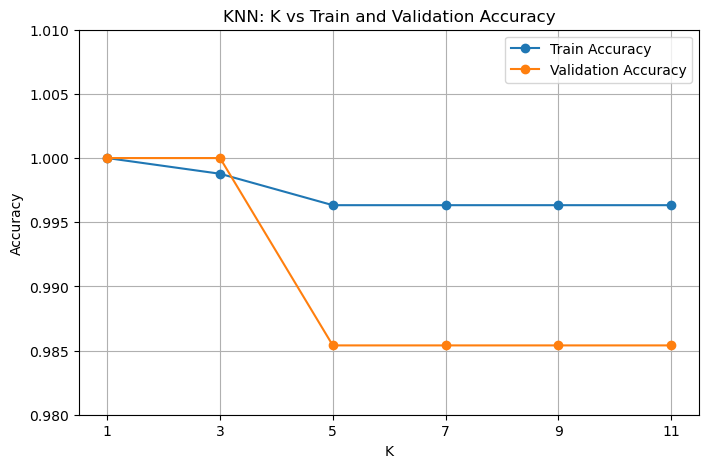

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    train_accuracies,
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    k_values,
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("KNN: K vs Train and Validation Accuracy")
plt.xticks(k_values)
plt.ylim(0.98, 1.01)
plt.legend()
plt.grid(True)

plt.show()

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

final_k = 3

knn_final = KNeighborsClassifier(n_neighbors=final_k)

knn_final.fit(X_train_scaled, y_train)

y_test_pred_knn = knn_final.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_test_pred_knn)
knn_precision = precision_score(y_test, y_test_pred_knn)
knn_recall = recall_score(y_test, y_test_pred_knn)
knn_f1 = f1_score(y_test, y_test_pred_knn)

print("KNN Final Model")
print(f"K = {final_k}")
print(f"Test Accuracy  = {knn_accuracy:.4f}")
print(f"Test Precision = {knn_precision:.4f}")
print(f"Test Recall    = {knn_recall:.4f}")
print(f"Test F1-score  = {knn_f1:.4f}")

cm_knn = confusion_matrix(y_test, y_test_pred_knn)

print("\nKNN Confusion Matrix:")
print(cm_knn)

error_0_to_1_knn = cm_knn[0, 1]
error_1_to_0_knn = cm_knn[1, 0]

print(f"Class 0 → Class 1 errors: {error_0_to_1_knn}")
print(f"Class 1 → Class 0 errors: {error_1_to_0_knn}")

KNN Final Model
K = 3
Test Accuracy  = 0.9964
Test Precision = 0.9919
Test Recall    = 1.0000
Test F1-score  = 0.9959

KNN Confusion Matrix:
[[158   1]
 [  0 122]]
Class 0 → Class 1 errors: 1
Class 1 → Class 0 errors: 0


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logreg = LogisticRegression(max_iter=1000)

logreg.fit(X_train_scaled, y_train)

y_val_pred_logreg = logreg.predict(X_val_scaled)

logreg_val_accuracy = accuracy_score(y_val, y_val_pred_logreg)
logreg_val_errors = (y_val_pred_logreg != y_val).sum()

print("Logistic Regression")
print(f"Validation Accuracy = {logreg_val_accuracy:.4f}")
print(f"Validation Errors   = {logreg_val_errors}")

Logistic Regression
Validation Accuracy = 0.9818
Validation Errors   = 5


In [12]:
y_test_pred_logreg = logreg.predict(X_test_scaled)

logreg_accuracy = accuracy_score(y_test, y_test_pred_logreg)
logreg_precision = precision_score(y_test, y_test_pred_logreg)
logreg_recall = recall_score(y_test, y_test_pred_logreg)
logreg_f1 = f1_score(y_test, y_test_pred_logreg)

print("Logistic Regression - Final Test Evaluation")
print(f"Test Accuracy  = {logreg_accuracy:.4f}")
print(f"Test Precision = {logreg_precision:.4f}")
print(f"Test Recall    = {logreg_recall:.4f}")
print(f"Test F1-score  = {logreg_f1:.4f}")

cm_logreg = confusion_matrix(y_test, y_test_pred_logreg)

print("\nLogistic Regression Confusion Matrix:")
print(cm_logreg)

error_0_to_1_logreg = cm_logreg[0, 1]
error_1_to_0_logreg = cm_logreg[1, 0]

print(f"Class 0 → Class 1 errors: {error_0_to_1_logreg}")
print(f"Class 1 → Class 0 errors: {error_1_to_0_logreg}")

Logistic Regression - Final Test Evaluation
Test Accuracy  = 0.9466
Test Precision = 0.8905
Test Recall    = 1.0000
Test F1-score  = 0.9421

Logistic Regression Confusion Matrix:
[[144  15]
 [  0 122]]
Class 0 → Class 1 errors: 15
Class 1 → Class 0 errors: 0


In [13]:
import os

os.makedirs("figures", exist_ok=True)

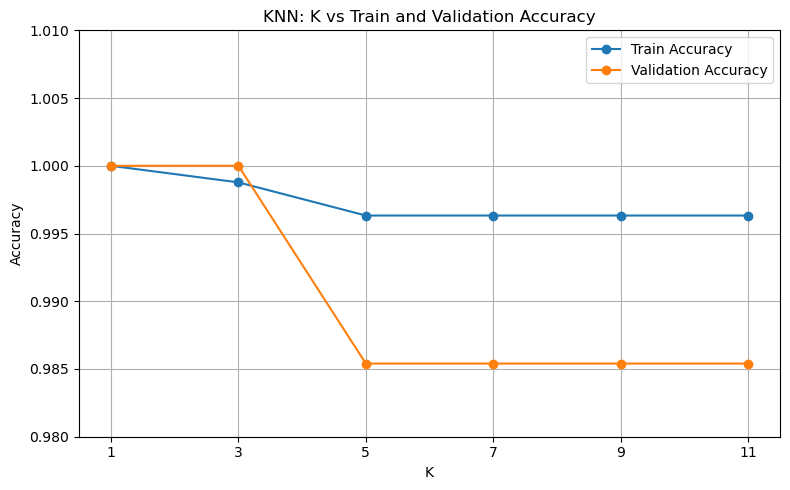

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    train_accuracies,
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    k_values,
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("KNN: K vs Train and Validation Accuracy")
plt.xticks(k_values)
plt.ylim(0.98, 1.01)
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "figures/knn_k_selection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

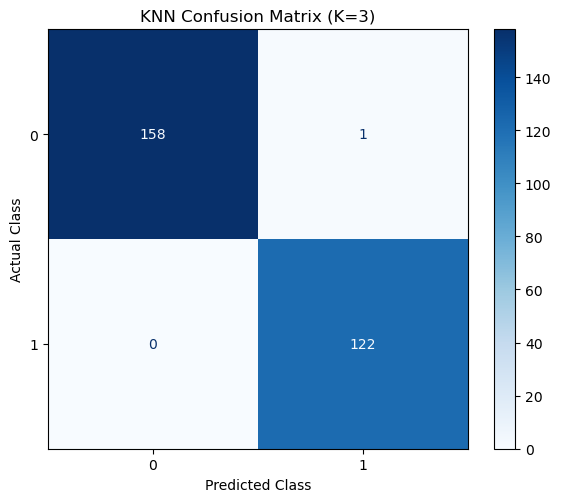

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_knn,
    display_labels=[0, 1],
    cmap="Blues",
    ax=ax
)

ax.set_title("KNN Confusion Matrix (K=3)")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    "figures/confusion_matrix_knn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

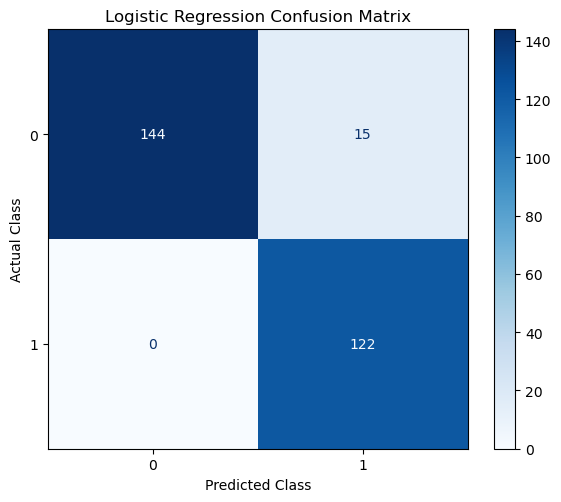

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_logreg,
    display_labels=[0, 1],
    cmap="Blues",
    ax=ax
)

ax.set_title("Logistic Regression Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    "figures/confusion_matrix_logistic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
from sklearn.metrics import confusion_matrix

cm_k5_unscaled = confusion_matrix(y_val, y_val_pred_unscaled)
cm_k5_scaled = confusion_matrix(y_val, y_val_pred_scaled)

comparison = pd.DataFrame({
    "Model": [
        "KNN",
        "KNN",
        "KNN",
        "Logistic Regression"
    ],
    "Parameter": [
        "K=5, Unscaled",
        "K=5, Scaled",
        "K=3, Scaled",
        "max_iter=1000"
    ],
    "Validation Accuracy": [
        accuracy_unscaled,
        accuracy_scaled,
        results.loc[results["K"] == final_k, "Validation Accuracy"].iloc[0],
        logreg_val_accuracy
    ],
    "Test Accuracy": [
        None,
        None,
        knn_accuracy,
        logreg_accuracy
    ],
    "0 → 1 Errors": [
        cm_k5_unscaled[0, 1],
        cm_k5_scaled[0, 1],
        cm_knn[0, 1],
        cm_logreg[0, 1]
    ],
    "1 → 0 Errors": [
        cm_k5_unscaled[1, 0],
        cm_k5_scaled[1, 0],
        cm_knn[1, 0],
        cm_logreg[1, 0]
    ]
})

comparison

,Model,Parameter,Validation Accuracy,Test Accuracy,0 → 1 Errors,1 → 0 Errors
0,KNN,"K=5, Unscaled",0.985401,NaN,4,0
1,KNN,"K=5, Scaled",0.985401,NaN,4,0
2,KNN,"K=3, Scaled",1.000000,0.996441,1,0
3,Logistic Regression,max_iter=1000,0.981752,0.946619,15,0


In [18]:
comparison.to_csv(
    "figures/model_comparison.csv",
    index=False
)

In [19]:
print("Logistic Accuracy variable:", logreg_accuracy)
print("Accuracy from confusion matrix:",
      (cm_logreg[0, 0] + cm_logreg[1, 1]) / cm_logreg.sum())

Logistic Accuracy variable: 0.9466192170818505
Accuracy from confusion matrix: 0.9466192170818505


In [20]:
comparison = pd.DataFrame({
    "Model": ["KNN", "Logistic Regression"],
    "Parameter": ["K=3", "max_iter=1000"],
    "Validation Accuracy": [
        results.loc[results["K"] == final_k, "Validation Accuracy"].iloc[0],
        logreg_val_accuracy
    ],
    "Test Accuracy": [
        knn_accuracy,
        accuracy_score(y_test, y_test_pred_logreg)
    ],
    "0 → 1 Errors": [
        cm_knn[0, 1],
        cm_logreg[0, 1]
    ],
    "1 → 0 Errors": [
        cm_knn[1, 0],
        cm_logreg[1, 0]
    ]
})

comparison

,Model,Parameter,Validation Accuracy,Test Accuracy,0 → 1 Errors,1 → 0 Errors
0,KNN,K=3,1.000000,0.996441,1,0
1,Logistic Regression,max_iter=1000,0.981752,0.946619,15,0


In [21]:
comparison.to_csv(
    "figures/model_comparison.csv",
    index=False
)